# 17장 Jev 에이전틱 능동 학습 루프

5부의 첫 장이다. 3부에서는 루프의 3단계(질의 전략)만, 4부에서는 4단계(오라클)만 Jev에게 맡겼다. 이 장은 두 자리를 함께 맡긴다.

Jev 불일치 질의는 후보마다 Jev 라벨 확률을 받는다. 그중 고른 문장의 확률은 오라클이 받을 답과 같은 질문의 답이다. 질의에 쓴 판정을 오라클 라벨로 다시 쓰면(판정 재사용) 오라클 호출이 없어진다. 대신 Jev가 틀리고 학생이 맞은 문장이 뽑혀 그 틀린 라벨이 그대로 학습에 들어갈 수 있다(확증 편향). 이 장은 그 대가를 재고, 라벨 없이 루프를 멈추는 종료 조건을 비교한다.

- 17.1 3·4단계 동시 대체 구조
- 17.2 에이전트 상태와 기록
- 17.3 종료 조건 — 성능 정체·예산·신뢰도
- 17.4 실패 유형 — 확증 편향과 오류 누적
- 17.5 네 가지 조합의 전체 루프 실험
- 17.6 사람 개입 지점

학생 모델은 1부와 같은 TF-IDF·로지스틱 회귀이고 CPU로 돈다. 초기 라벨 100개는 사람(정답 라벨)이 붙인다. Jev 판정은 4부의 슬림 형식과 13장 설정을 쓰고, 같은 설정으로 4부에서 받아 둔 판정은 저장소에서 물려받는다. Jev 호출에 필요한 키·주소·모델 이름은 `jupyter/.env` 에서만 읽는다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


3장의 엔트로피 점수를 다시 싣는다. 엔트로피 질의와 Jev 불일치의 후보 축소에 쓴다.

In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

query_entropy = make_score_query(score_entropy)

Jev 호출 함수, 라벨 체계, 요청 형식은 14장과 같다. 요청 형식에는 14장의 지시문 변형(바꿔 쓴 설명)이 들어 있어 별도 판정 대조군에 쓴다.

In [3]:
# ── Jev 호출 함수 ────
import os
import requests
from dotenv import load_dotenv
from concurrent.futures import ThreadPoolExecutor

load_dotenv(".env")                      # jupyter/.env — 키·주소·모델 이름은 여기에만 있다
print({n: bool(os.getenv(n)) for n in ("JEV_API_KEY", "JEV_BASE_URL", "JEV_MODEL")})   # 값은 출력하지 않는다

JEV = dict(key=os.environ["JEV_API_KEY"], url=os.environ["JEV_BASE_URL"].rstrip("/"), model=os.environ["JEV_MODEL"])
MAX_CONC = 5                             # 동시 호출 수
SESSION = requests.Session()

def mask(text):
    # 오류 메시지에 키·주소·모델 이름이 섞여 나오지 않도록 가린다
    for v in JEV.values():
        text = text.replace(v, "***")
    return text

def jev_ask(state, questions):
    # 판정 질문 묶음을 한 번 보내고 (질문 이름별 답, 입력 토큰, 출력 토큰)을 돌려준다
    body = dict(model=JEV["model"], state=state, questions=questions)
    for wait in (2, 4, 8, 16, 32, 64, 120, 240, 480, 600):   # 일시 오류·연결 끊김은 쉬었다 다시 보낸다(최대 약 26분)
        try:
            r = SESSION.post(f"{JEV['url']}/v1/systemone", headers={"Authorization": f"Bearer {JEV['key']}"},
                             json=body, timeout=300)
        except requests.ConnectionError:                    # 오래 도는 실험에서 연결이 끊기면 잠시 쉬고 다시 보낸다
            time.sleep(wait)
            continue
        if r.status_code == 200:
            j = r.json()
            return j["answers"], j["usage"]["input_tokens"], j["usage"]["output_tokens"]
        time.sleep(wait)
    raise RuntimeError(mask(f"Jev 응답 {r.status_code}: {r.text[:300]}"))

{'JEV_API_KEY': True, 'JEV_BASE_URL': True, 'JEV_MODEL': True}


In [4]:
# ── 라벨 체계 ────
LABEL_NAMES = {"nsmc": ["부정", "긍정"],
               "ynat": ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]}
LABEL_DESC = {"nsmc": {"부정": "영화를 부정적으로 평가한 리뷰", "긍정": "영화를 긍정적으로 평가한 리뷰"},
              "ynat": {"IT과학": "정보기술·과학 기사", "경제": "경제·산업·금융 기사", "사회": "사건·사고·사회 기사",
                       "생활문화": "생활·문화·건강·여행 기사", "세계": "국제·해외 기사", "스포츠": "스포츠 기사",
                       "정치": "정치·외교·북한 기사"}}
TASK = {"nsmc": "영화 리뷰의 감성", "ynat": "뉴스 기사 제목의 주제"}

In [5]:
# ── 라벨 스키마와 요청 만들기 (13장 + 지시문 변형·자기 평가 질문) ────
CHUNK = 50                               # 요청 하나에 넣는 문장 수
TASK_SENT = {"nsmc": "영화 리뷰의 감성을 분류한다.", "ynat": "뉴스 기사 제목의 주제를 분류한다."}
RULES = {"nsmc": ["반어나 비꼼으로 칭찬하는 척하는 리뷰는 부정이다",
                  "칭찬과 불만이 섞이면 글쓴이의 최종 평가를 따른다",
                  "영화 밖의 이야기(배우, 다른 관객)라도 영화에 대한 태도가 드러나면 그 태도를 따른다"],
         "ynat": ["기업·산업·시장·금융·부동산은 경제다. IT 제품·통신·인터넷 서비스·과학 연구는 IT과학이다",
                  "사건·사고·교육·노동·법원·지역 소식은 사회다",
                  "국내 정치·국회·정당·외교·북한은 정치다. 외국 정부와 해외에서 일어난 일은 세계다",
                  "문화·연예·건강·여행·종교·생활 정보는 생활문화다",
                  "경기 결과·선수·구단·대회는 스포츠다"]}
# 지시문 변형 v1: 같은 뜻을 다른 말로 쓴 과제 문장과 라벨 설명
TASK_ALT = {"nsmc": "리뷰를 쓴 사람이 영화를 좋게 봤는지 나쁘게 봤는지 가린다.",
            "ynat": "기사 제목을 보고 어느 지면에 실릴 기사인지 가린다."}
LABEL_DESC_ALT = {"nsmc": {"부정": "영화가 별로였다는 리뷰", "긍정": "영화가 좋았다는 리뷰"},
                  "ynat": {"IT과학": "컴퓨터·인터넷·통신·과학 소식", "경제": "기업·시장·돈의 흐름에 관한 소식",
                           "사회": "사건·사고와 사회 문제", "생활문화": "생활 정보·문화·건강·여행",
                           "세계": "다른 나라 소식", "스포츠": "경기와 선수 소식", "정치": "정부·국회·정당·외교·북한 소식"}}
SURE_LEVELS = ["어느 라벨인지 알 수 없다", "두 라벨 사이에서 헷갈린다", "한 라벨에 기울지만 다른 라벨일 수 있다",
               "거의 분명하다", "의심할 여지 없이 분명하다"]

def schema_text(name, level, desc, task, names):
    lines = [f"과제: {task[name]}", "라벨:"]
    lines += [f"- {n}: {desc[name][n]}" if level >= 1 else f"- {n}" for n in names]
    lines += ["경계 규칙:"] + [f"- {r}" for r in RULES[name]] if level == 2 else []
    return "\n".join(lines)

def build_request(name, texts, schema=1, shots=(), desc=LABEL_DESC, task=TASK_SENT, reverse=False, sure=False):
    # reverse: 라벨 목록과 선택지 순서를 뒤집는다. sure: 문장마다 자기 평가 질문 sure_i를 더한다
    names = LABEL_NAMES[name][::-1] if reverse else LABEL_NAMES[name]
    one = lambda t: str(t).replace("\n", " ")
    parts = [schema_text(name, schema, desc, task, names)]
    parts += ["예시:\n" + "\n".join(f'- "{one(t)}" → {y}' for t, y in shots)] if len(shots) else []
    state = "\n\n".join(parts + ["분류할 문장:\n" + "\n".join(f"[{i}] {one(t)}" for i, t in enumerate(texts))])
    qs = {f"label_{i}": {"type": "choice", "instructions": f"[{i}]번 문장의 라벨", "criteria": {n: None for n in names}}
          for i in range(len(texts))}
    qs.update({f"sure_{i}": {"type": "score", "instructions": f"[{i}]번 문장의 라벨은 얼마나 분명한가?", "criteria": SURE_LEVELS}
               for i in range(len(texts))} if sure else {})
    return state, qs

In [6]:
# ── Jev 라벨 판정 ────
def jev_label(name, texts, cfg):
    # texts를 50개씩 묶어 판정한다. (선택지 확률 행렬, 묶음별 사용량)
    names = LABEL_NAMES[name]
    def one(s):
        state, qs = build_request(name, texts[s:s + CHUNK], **cfg)
        t0 = time.perf_counter()
        ans, a, b = jev_ask(state, qs)
        P = [[ans[f"label_{i}"]["probabilities"].get(m, 0.0) for m in names] for i in range(len(qs))]
        return P, dict(n_in=a, n_out=b, t=time.perf_counter() - t0, n=len(qs))
    with ThreadPoolExecutor(MAX_CONC) as ex:
        out = list(ex.map(one, range(0, len(texts), CHUNK)))
    P = np.array([p for o in out for p in o[0]])
    return P / P.sum(1, keepdims=True), pd.DataFrame([o[1] for o in out])

In [7]:
# ── 16장에서 넘겨받는 설정과 비용 가정 ────
BEST = {"nsmc": dict(schema=1, n=8), "ynat": dict(schema=2, n=7)}     # 13장: NSMC S1 + 균형 8, YNAT S2 + 균형 7
MIX_TRAIN = {"nsmc": "기본", "ynat": "라벨 평활화"}                    # 16장 혼합 오라클 기본값: 신뢰도 하위 20% 검수 + 학습 방식
R_REVIEW = 20
UNIT = {"nsmc": 50, "ynat": 80}                                       # 00_기획안 4.2절 가정: 사람 라벨 단가(원)
REVIEW = 0.6                                                          # 검수는 라벨 단가의 60%
M = 150                                                               # Jev 불일치 후보 수(10장)

def pick_bal(d, idx0, n, rng):
    y0 = d["y_pool"][idx0]
    pick = np.concatenate([rng.choice(idx0[y0 == c], n // d["n_classes"], replace=False) for c in range(d["n_classes"])])
    return rng.permutation(pick)

def oracle_cfg(d, idx0, seed, **extra):
    # 13장 Jev 오라클과 같다: 그 실행의 초기 라벨 100개에서 클래스 균형 예시를 고른다
    pick = pick_bal(d, idx0, BEST[d["name"]]["n"], np.random.default_rng(seed))
    return dict(schema=BEST[d["name"]]["schema"], shots=[(d["texts"][i], LABEL_NAMES[d["name"]][d["y_pool"][i]]) for i in pick], **extra)

ALT = dict(desc=LABEL_DESC_ALT, task=TASK_ALT)                        # 별도 판정의 지시문: 14장 변형 v1(바꿔 쓴 설명)

학생 모델의 학습 방식은 15.4절과 같다. 혼합 오라클의 YNAT 칸만 라벨 평활화를 쓴다.

In [8]:
# ── 학습 방식 ────
import scipy.sparse as sp

def train_weighted(X, y, w, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y, sample_weight=w)

def train_soft(X, Q, seed):
    # 확률 라벨: 행을 클래스 수만큼 복제하고 클래스 확률을 가중치로 준다
    C = Q.shape[1]
    w = Q.T.ravel()
    keep = w > 1e-6
    return train_weighted(sp.vstack([X] * C)[keep], np.repeat(np.arange(C), X.shape[0])[keep], w[keep], seed)

EPS = 0.1
TRAIN = {"기본": lambda X, Q, jev, seed: train_model(X, Q.argmax(1), seed),
         "샘플 가중": lambda X, Q, jev, seed: train_weighted(X, Q.argmax(1), Q.max(1), seed),
         "확률 라벨": lambda X, Q, jev, seed: train_soft(X, Q, seed),
         "라벨 평활화": lambda X, Q, jev, seed: train_soft(X, np.where(jev[:, None], (1 - EPS) * Q + EPS / Q.shape[1], Q), seed)}

In [9]:
# ── 검증 집합과 감시 집합 ────
# 검증 2,000개의 앞 1,000개는 성능 정체 판단(검증 F1)에, 1,000~1,500번째 500개는 감시 집합 S로 쓴다.
# S에서는 라벨을 보지 않고 학생 예측의 변화와 Jev 라벨과의 일치만 본다
for name, d in DATA.items():
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, max_features=50000, sublinear_tf=True)
    vec.fit(pd.read_csv(f"data/{name}_pool.csv").text)                         # load_data와 같은 설정
    v = pd.read_csv(f"data/{name}_val.csv")
    d["X_val"], d["y_val"] = vec.transform(v.text[:1000]), v.label.values[:1000]
    d["X_stop"] = vec.transform(v.text[1000:1500])
    js = pd.read_csv(f"results/ch14_parts/static_{name}_rep0.csv").iloc[1000:1500]   # 14장에서 받아 둔 Jev 라벨(새 호출 없음)
    d["jev_stop"] = js.filter(regex=r"^p\d").values.argmax(1)
    print(f"{name}: 검증 F1용 {d['X_val'].shape[0]} | 감시 집합 {d['X_stop'].shape[0]} | 감시 집합 Jev 라벨 정확도 "
          f"{(d['jev_stop'] == v.label.values[1000:1500]).mean():.4f}")

nsmc: 검증 F1용 1000 | 감시 집합 500 | 감시 집합 Jev 라벨 정확도 0.9000


ynat: 검증 F1용 1000 | 감시 집합 500 | 감시 집합 Jev 라벨 정확도 0.8200


## 17.1 3·4단계 동시 대체 구조

루프의 모양은 그대로다. 바뀌는 것은 3단계의 `query_fn` 과 4단계의 라벨 출처다.

| 단계 | 전통 루프 | 에이전틱 루프 |
|---|---|---|
| 3. 질의 | 엔트로피 상위 k | 엔트로피 상위 150개를 Jev가 판정하고 KL(p_Jev ‖ p_θ) 상위 k |
| 4. 라벨 | 사람 | 질의 때 받은 Jev 확률을 그대로 라벨로(판정 재사용) |

Jev 판정은 문장마다 한 번만 받는다. 같은 시드에서 같은 문장이 다시 후보에 오르면 저장소의 판정을 쓴다. 저장소는 같은 설정(13장 스키마, 그 시드의 초기 라벨에서 고른 예시)으로 15·16장이 받은 판정을 물려받아 시작한다. 칸마다의 비용은 실제로 보낸 요청이 아니라 그 칸이 쓴 판정의 토큰 몫으로 센다(15장과 같은 방식). 이번에 새로 쓴 토큰은 따로 기록한다.

별도 판정 대조군은 고른 문장을 지시문을 바꾼 요청(14장 변형 v1)으로 한 번 더 판정해 라벨로 쓴다. 판정 재사용과 같은 문장을 고르지만 라벨은 다른 요청에서 온다.

In [10]:
# ── Jev 판정 저장소 ────
import os
os.makedirs("results/ch17_parts", exist_ok=True)

def cache_path(name, seed, v):
    return f"results/ch17_parts/jev_{name}_{seed}_{v}.csv"

def load_cache(name, seed, v):
    # v = "base"(13장 설정) | "alt"(별도 판정 지시문). base는 처음 열 때 같은 설정의 16장·15장 저장소를 물려받는다.
    # 15장 판정을 나중에 넣어 덮어쓰므로 엔트로피 칸은 15장 실행과 같은 라벨을 받는다
    path = cache_path(name, seed, v)
    src = [path] if os.path.exists(path) else \
          [f"results/ch16_parts/jev_{name}_{seed}.csv", f"results/ch15_parts/jev_{name}_{seed}.csv"] if v == "base" else []
    cache = {}
    for f in src:
        df = pd.read_csv(f)
        P = df.filter(regex=r"^p\d").values.astype(float)
        cache.update({int(i): (p, t) for i, p, t in zip(df.idx.values, P, df.n_in.values)})
    return cache

def save_cache(name, seed, v, cache):
    rows = [dict(idx=i, n_in=t, **{f"p{j}": x for j, x in enumerate(p)}) for i, (p, t) in cache.items()]
    pd.DataFrame(rows).to_csv(cache_path(name, seed, v), index=False)

def jev_lookup(d, q, cache, cfg):
    # 저장소에 없는 문장만 Jev에 묻는다. (확률 행렬, 이 판정들의 토큰 몫 합, 이번에 새로 쓴 토큰)
    miss = np.array([i for i in q if int(i) not in cache], dtype=int)
    new = 0.0
    if len(miss):
        P, u = jev_label(d["name"], d["texts"][miss], cfg)
        cache.update({int(i): (p, t) for i, p, t in zip(miss, P, np.repeat(u.n_in.values / u.n.values, u.n.values))})
        new = u.n_in.sum()
    return np.array([cache[int(i)][0] for i in q]), sum(cache[int(i)][1] for i in q), new

In [11]:
# ── Jev 불일치 질의와 판정 재사용 ────
def kl_div(PJ, P):
    return (PJ * (np.log(PJ + 1e-12) - np.log(P + 1e-12))).sum(1)

def make_jev_kl(cache, cfg, memo):
    # 10장 Jev 불일치를 슬림 형식으로 바꾼 질의 함수. 고른 문장의 Jev 확률을 memo에 남긴다
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        h = score_entropy(P)
        top = np.argsort(-h)[:M]                                    # 후보 축소: 엔트로피 상위 M
        cand = idx_u[top]
        PJ, tok, new = jev_lookup(data, cand, cache, cfg)           # 후보마다 Jev 라벨 판정
        sel = np.lexsort((-h[top], -kl_div(PJ, P[top])))[:k]        # KL 내림차순, 같으면 엔트로피 내림차순
        memo.clear()
        memo.update(P={int(i): p for i, p in zip(cand[sel], PJ[sel])}, tok=tok, new=new)
        return cand[sel]
    return query_fn

def oracle_reuse(memo):
    # 판정 재사용 오라클: 질의 때 받은 확률을 그대로 라벨로 쓴다. oracle_fn으로 쓰면 (argmax, max)를 돌려준다
    def label_fn(q):
        return np.array([memo["P"][int(i)] for i in q]), 0.0, 0.0
    return label_fn

## 17.2 에이전트 상태와 기록

라운드마다 남기는 상태는 다음과 같다.

| 기록 | 내용 |
|---|---|
| f1, acc | 시험 집합 성능 |
| f1_val | 검증 1,000개 F1. 성능 정체 종료 조건에 쓴다 |
| 감시 집합 예측 | 검증 500개(감시 집합)에 대한 학생 예측. 예측 안정화 종료 조건에 쓴다 |
| agree_jev | 감시 집합에서 학생 예측과 Jev 라벨의 일치율. 14장에서 받아 둔 Jev 라벨이라 새 호출이 없다 |
| noise, reviews | 학습 집합의 라벨 노이즈율, 누적 검수 수 |
| tok_q, tok_o, tok_new | 질의 판정·오라클 판정의 토큰 몫, 이번에 새로 쓴 토큰 |
| batch_* | 이번 배치의 Jev 오답률, 확증 편향(Jev 오답·학생 정답) 비율, 학생 오답률 |

혼합 오라클은 16장 기본값대로 이번 라운드 Jev 라벨 가운데 신뢰도 하위 20%를 사람이 검수한다.

In [12]:
# ── 에이전틱 루프 ────
def route_conf(Q, m, r):
    # 16장 기본값: 이번 라운드 Jev 라벨 가운데 신뢰도가 낮은 r%를 검수로 보낸다
    new = np.arange(len(Q) - m, len(Q))
    return new[np.argsort(Q[new].max(1), kind="stable")[:round(m * r / 100)]]

# 칸 이름: (질의, 라벨 출처, 검수 비율, 학습 방식). 학습 방식 None은 데이터별 혼합 기본값
ARMS = {"엔트로피·사람": ("엔트로피", "사람", 0, "기본"),
        "엔트로피·Jev": ("엔트로피", "Jev", 0, "기본"),
        "엔트로피·혼합": ("엔트로피", "Jev", R_REVIEW, None),
        "Jev 불일치·사람": ("Jev 불일치", "사람", 0, "기본"),
        "Jev 불일치·Jev": ("Jev 불일치", "재사용", 0, "기본"),
        "Jev 불일치·Jev 별도 판정": ("Jev 불일치", "별도", 0, "기본"),
        "Jev 불일치·혼합": ("Jev 불일치", "재사용", R_REVIEW, None)}

def run_agent(d, seed, arm, caches, n_init=N_INIT, k=K, budget=BUDGET):
    qname, src, r, train = ARMS[arm]
    train = train or MIX_TRAIN[d["name"]]
    rng = np.random.default_rng(seed)
    n, C, y_true = d["X_pool"].shape[0], d["n_classes"], d["y_pool"]
    idx_l = rng.choice(n, n_init, replace=False)
    Q, jev = np.eye(C)[y_true[idx_l]], np.zeros(n_init, bool)              # 초기 100개는 사람 라벨
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    cfg = {"base": oracle_cfg(d, idx_l, seed), "alt": oracle_cfg(d, idx_l, seed, **ALT)}
    memo = {}
    query_fn = query_entropy if qname == "엔트로피" else make_jev_kl(caches["base"], cfg["base"], memo)
    label_fn = {"사람": lambda q: (np.eye(C)[y_true[q]], 0.0, 0.0),
                "Jev": lambda q: jev_lookup(d, q, caches["base"], cfg["base"]),
                "별도": lambda q: jev_lookup(d, q, caches["alt"], cfg["alt"]),
                "재사용": oracle_reuse(memo)}[src]
    log, stop_pred, tok_q, tok_o, tok_new, n_rev = [], [], 0.0, 0.0, 0.0, 0
    while True:
        model = TRAIN[train](d["X_pool"][idx_l], Q, jev, seed)                                   # 1. train
        y_hat, s_hat = model.predict(d["X_test"]), model.predict(d["X_stop"])
        stop_pred.append(s_hat)
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(d["y_test"], y_hat),
                        f1=f1_score(d["y_test"], y_hat, average="macro"),
                        f1_val=f1_score(d["y_val"], model.predict(d["X_val"]), average="macro"),
                        agree_jev=(s_hat == d["jev_stop"]).mean(),
                        noise=(Q.argmax(1) != y_true[idx_l]).mean(), reviews=n_rev,
                        tok_q=tok_q, tok_o=tok_o, tok_new=tok_new))
        if len(idx_l) >= budget:
            break
        m = min(k, budget - len(idx_l))
        q = query_fn(model, d, idx_l, Q.argmax(1), idx_u, m, rng)                                 # 2. predict · 3. query
        tok_q, tok_new = tok_q + memo.get("tok", 0.0), tok_new + memo.get("new", 0.0)
        Pj, a, b = label_fn(q)                                                                     # 4a. 라벨
        tok_o, tok_new = tok_o + a, tok_new + b
        # 확증 편향 기록: 이번 배치에 들어간 Jev 라벨(검수 전)과 학생 예측을 정답과 맞춰 본다
        yq, pq = y_true[q], model.predict(d["X_pool"][q])
        jl = Pj.argmax(1) if src != "사람" else (np.array([memo["P"][int(i)] for i in q]).argmax(1) if memo else None)
        log[-1].update(batch_jev_wrong=np.nan if jl is None else (jl != yq).mean(),
                       batch_bias=np.nan if jl is None else ((jl != yq) & (pq == yq)).mean(),
                       batch_student_wrong=(pq != yq).mean())
        idx_l, Q = np.r_[idx_l, q], np.vstack([Q, Pj])
        jev = np.r_[jev, np.full(m, src != "사람")]
        sel = route_conf(Q, m, r)                                                                  # 4b. 사람 검수
        Q[sel], jev[sel], n_rev = np.eye(C)[y_true[idx_l[sel]]], False, n_rev + len(sel)
        idx_u = np.setdiff1d(idx_u, q)                                                             # 5. update
    return pd.DataFrame(log), np.array(stop_pred)

먼저 데이터마다 시드 0의 초기 모델로 Jev 불일치 질의를 한 번 돌려 본다. 후보 150개 가운데 저장소에 없는 문장이 몇 개인지, 새 판정 하나에 입력 토큰이 얼마나 드는지 본다. 이 점검은 저장소에 쓰지 않는다.

In [13]:
# ── 첫 호출 점검 ────
for name, d in DATA.items():
    rng = np.random.default_rng(0)
    idx_l = rng.choice(d["X_pool"].shape[0], N_INIT, replace=False)
    idx_u = np.setdiff1d(np.arange(d["X_pool"].shape[0]), idx_l)
    model = train_model(d["X_pool"][idx_l], d["y_pool"][idx_l], 0)
    cache, memo = load_cache(name, 0, "base"), {}
    n0 = len(cache)
    t0 = time.perf_counter()
    q = make_jev_kl(cache, oracle_cfg(d, idx_l, 0), memo)(model, d, idx_l, None, idx_u, K, rng)
    n_new = len(cache) - n0
    print(f"{name}: 저장소 {n0:,}개 | 후보 {M}개 중 새 판정 {n_new}개 | 새 입력 토큰 {memo['new']:,.0f}"
          f"(문장당 {memo['new'] / max(n_new, 1):.1f}) | {time.perf_counter() - t0:.1f}초 | "
          f"고른 {len(q)}개의 Jev 라벨 정확도 {np.mean([memo['P'][int(i)].argmax() == d['y_pool'][i] for i in q]):.2f}")

nsmc: 저장소 14,460개 | 후보 150개 중 새 판정 15개 | 새 입력 토큰 1,623(문장당 108.2) | 0.2초 | 고른 50개의 Jev 라벨 정확도 1.00


ynat: 저장소 9,810개 | 후보 150개 중 새 판정 77개 | 새 입력 토큰 9,040(문장당 117.4) | 0.2초 | 고른 50개의 Jev 라벨 정확도 0.90


일곱 칸을 모두 돌린다. (데이터, 시드)마다 한 작업으로 묶어 칸을 차례로 돌리고, 작업 10개는 CPU 코어에 나눠 동시에 돈다. 같은 시드의 칸들이 판정 저장소를 함께 쓰기 때문이다. 결과는 (데이터, 칸, 시드)마다 `results/ch17_parts/` 에 저장해 끊겨도 이어 돈다.

In [14]:
# ── 전체 실행 ────
def arm_tag(arm):
    return arm.replace(" ", "_").replace("·", "-")

def run_job(name, seed):
    d = DATA[name]
    caches = {v: load_cache(name, seed, v) for v in ("base", "alt")}
    out = []
    for arm in ARMS:
        path = f"results/ch17_parts/loop_{name}_{arm_tag(arm)}_{seed}.csv"
        if not os.path.exists(path):
            t0 = time.perf_counter()
            df, sp = run_agent(d, seed, arm, caches)
            np.save(path.replace("loop_", "stop_").replace(".csv", ".npy"), sp)
            df.assign(data=name, arm=arm, wall=time.perf_counter() - t0).to_csv(path, index=False)
            for v in caches:
                save_cache(name, seed, v, caches[v])
        out.append(pd.read_csv(path))
    return pd.concat(out, ignore_index=True)

t0 = time.perf_counter()
jobs = [(name, s) for name in DATA for s in SEEDS]
res = pd.concat(Parallel(n_jobs=len(jobs))(delayed(run_job)(n, s) for n, s in jobs), ignore_index=True)
print(f"완료 {(time.perf_counter() - t0) / 60:.1f}분 | 이번에 새로 쓴 입력 토큰 "
      f"{res[res.n_labeled == BUDGET].tok_new.sum():,.0f}")
print(res.groupby(["data", "arm"], sort=False).agg(runs=("seed", "nunique"), n_max=("n_labeled", "max")).to_string())

완료 13.8분 | 이번에 새로 쓴 입력 토큰 3,396,787
                        runs  n_max
data arm                           
nsmc 엔트로피·사람               5   2000
     엔트로피·Jev              5   2000
     엔트로피·혼합               5   2000
     Jev 불일치·사람            5   2000
     Jev 불일치·Jev           5   2000
     Jev 불일치·Jev 별도 판정     5   2000
     Jev 불일치·혼합            5   2000
ynat 엔트로피·사람               5   2000
     엔트로피·Jev              5   2000
     엔트로피·혼합               5   2000
     Jev 불일치·사람            5   2000
     Jev 불일치·Jev           5   2000
     Jev 불일치·Jev 별도 판정     5   2000
     Jev 불일치·혼합            5   2000


16장·10장 결과와 맞춰 본다. 엔트로피 세 칸은 15·16장 판정을 물려받았으므로 16장과 같은 값이 나와야 한다. Jev 불일치·사람은 10장과 같은 전략이지만 판정 요청이 3부 형식에서 슬림 형식으로 바뀌었다. 그 차이가 ALC에 얼마나 남는지 본다.

In [15]:
# ── 앞 장 결과와 비교 ────
def alc_mean(g):
    return np.mean([alc(x.n_labeled.values, x.f1.values) for _, x in g.groupby("seed")])

ARM15 = {"nsmc": {"엔트로피·Jev": "r0", "엔트로피·혼합": "신뢰도_20"},
         "ynat": {"엔트로피·Jev": "r0", "엔트로피·혼합": "신뢰도_20_·_라벨_평활화"}}
chk = []
for name in DATA:
    r = res[res.data == name]
    for arm, tag in ARM15[name].items():
        old = pd.concat([pd.read_csv(f"results/ch15_parts/loop_{name}_{tag}_{s}.csv") for s in SEEDS])
        chk.append(dict(data=name, arm=arm, 이장=alc_mean(r[r.arm == arm]), 앞장=alc_mean(old), 출처="15·16장"))
    old = pd.concat([pd.read_csv(f"results/ch10_parts/{name}_kl150_{s}.csv") for s in SEEDS])
    chk.append(dict(data=name, arm="Jev 불일치·사람", 이장=alc_mean(r[r.arm == "Jev 불일치·사람"]), 앞장=alc_mean(old),
                    출처="10장(3부 형식)"))
chk = pd.DataFrame(chk).assign(diff=lambda x: x.이장 - x.앞장)
print(chk.round(4).to_string(index=False))

data        arm     이장     앞장         출처   diff
nsmc   엔트로피·Jev 0.7450 0.7450     15·16장 0.0000
nsmc    엔트로피·혼합 0.7528 0.7528     15·16장 0.0000
nsmc Jev 불일치·사람 0.7711 0.7694 10장(3부 형식) 0.0016
ynat   엔트로피·Jev 0.5574 0.5574     15·16장 0.0000
ynat    엔트로피·혼합 0.6046 0.6046     15·16장 0.0000
ynat Jev 불일치·사람 0.6116 0.6078 10장(3부 형식) 0.0038


## 17.3 종료 조건 — 성능 정체·예산·신뢰도

루프를 언제 멈출지는 지금까지 예산(라벨 2,000개) 하나로 정했다. 실제로는 예산을 다 쓰기 전에 성능이 더 오르지 않는 때가 온다. 네 조건을 같은 로그에서 사후로 시뮬레이션한다.

| 조건 | 규칙 | 라벨 |
|---|---|---|
| 예산 | 라벨 2,000개 | 필요 없음 |
| 성능 정체 | 검증 F1이 최근 3라운드 동안 그 전 최고값보다 δ 이상 오르지 않으면 멈춘다 | 검증 라벨 필요 |
| 예측 안정화 | 감시 집합에서 이웃한 두 라운드 학생 예측의 카파가 최근 3라운드 평균 κ* 이상이면 멈춘다 | 필요 없음 |
| Jev 일치 | 감시 집합의 학생·Jev 일치율이 최근 3라운드 동안 그 전 최고값보다 0.005 이상 오르지 않으면 멈춘다 | 필요 없음 |

라운드 5(라벨 350개)부터 판단한다. 평가는 멈춘 라벨 수와 그때의 시험 F1이 예산 끝 F1의 몇 %인가다.

In [16]:
# ── 종료 조건 시뮬레이션 ────
from sklearn.metrics import cohen_kappa_score
W, START = 3, 5

def stop_round(series, rule):
    # rule(series, t)가 참인 첫 라운드. 없으면 마지막 라운드
    for t in range(START, len(series)):
        if rule(series, t):
            return t
    return len(series) - 1

def no_gain(eps):
    return lambda s, t: s[t - W + 1:t + 1].max() < s[:t - W + 1].max() + eps

def kappa_series(sp):
    return np.r_[np.nan, [cohen_kappa_score(sp[t - 1], sp[t]) for t in range(1, len(sp))]]

RULES = {"성능 정체 δ=0.005": ("f1_val", no_gain(0.005)), "성능 정체 δ=0.01": ("f1_val", no_gain(0.01)),
         "예측 안정화 κ*=0.97": ("kappa", lambda s, t: np.nanmean(s[t - W + 1:t + 1]) >= 0.97),
         "예측 안정화 κ*=0.99": ("kappa", lambda s, t: np.nanmean(s[t - W + 1:t + 1]) >= 0.99),
         "Jev 일치": ("agree_jev", no_gain(0.005))}
rows = []
for (name, arm, seed), g in res.groupby(["data", "arm", "seed"], sort=False):
    g = g.sort_values("n_labeled").reset_index(drop=True)
    g["kappa"] = kappa_series(np.load(f"results/ch17_parts/stop_{name}_{arm_tag(arm)}_{seed}.npy"))
    for rule, (col, fn) in RULES.items():
        t = stop_round(g[col].values, fn)
        rows.append(dict(data=name, arm=arm, seed=seed, rule=rule, n_stop=g.n_labeled[t],
                         f1_ratio=g.f1[t] / g.f1.iloc[-1], f1_stop=g.f1[t]))
stops = pd.DataFrame(rows)
tab2 = stops.groupby(["data", "rule", "arm"], sort=False)[["n_stop", "f1_ratio"]].mean()
for name in DATA:
    print(f"\n{name} 종료 조건별 멈춘 라벨 수와 예산 끝 F1 대비 비율 (시드 평균)")
    print(tab2.loc[name].unstack("rule").round(3).to_string())


nsmc 종료 조건별 멈춘 라벨 수와 예산 끝 F1 대비 비율 (시드 평균)
                         n_stop                                                        f1_ratio                                                  
rule              성능 정체 δ=0.005 성능 정체 δ=0.01 예측 안정화 κ*=0.97 예측 안정화 κ*=0.99 Jev 일치 성능 정체 δ=0.005 성능 정체 δ=0.01 예측 안정화 κ*=0.97 예측 안정화 κ*=0.99 Jev 일치
arm                                                                                                                                              
엔트로피·사람                   670.0        540.0         2000.0         2000.0  520.0         0.937        0.927            1.0            1.0  0.926
엔트로피·Jev                  640.0        620.0         2000.0         2000.0  630.0         0.940        0.938            1.0            1.0  0.935
엔트로피·혼합                   630.0        440.0         2000.0         2000.0  720.0         0.936        0.912            1.0            1.0  0.946
Jev 불일치·사람                870.0        670.0         2000.0         2000.0  720.

## 17.4 실패 유형 — 확증 편향과 오류 누적

Jev 불일치는 Jev와 학생의 의견이 다른 문장을 고른다. 학생이 틀린 문장을 찾아내면 좋은 질의지만, Jev가 틀리고 학생이 맞은 문장도 똑같이 높은 점수를 받는다. 판정 재사용에서는 그 틀린 Jev 라벨이 그대로 학습 집합에 들어간다. 이것이 이 루프의 확증 편향이다.

배치마다 질의된 문장 가운데 「Jev 오답·학생 정답」인 비율 β를 센다. 엔트로피 질의의 β와 비교하고, 라벨을 다른 지시문으로 다시 받는 별도 판정이 β를 얼마나 줄이는지 본다. 학습 집합 노이즈율의 라운드별 곡선으로 오류가 쌓이는 속도도 본다.


nsmc 질의 배치의 비율 (Jev 불일치·사람은 질의 판정의 Jev 라벨 기준, 시드·라운드 평균)
                   batch_jev_wrong  batch_bias  batch_student_wrong
arm                                                                
엔트로피·Jev                    0.1438      0.0691               0.5051
Jev 불일치·Jev                 0.0414      0.0228               0.5226
Jev 불일치·Jev 별도 판정           0.0415      0.0220               0.5227
Jev 불일치·혼합                  0.0397      0.0220               0.5312
Jev 불일치·사람                  0.0382      0.0196               0.5380

ynat 질의 배치의 비율 (Jev 불일치·사람은 질의 판정의 Jev 라벨 기준, 시드·라운드 평균)
                   batch_jev_wrong  batch_bias  batch_student_wrong
arm                                                                
엔트로피·Jev                    0.2733      0.0549               0.6749
Jev 불일치·Jev                 0.2439      0.0503               0.6871
Jev 불일치·Jev 별도 판정           0.2341      0.0464               0.6809
Jev 불일치·혼합                  0.2337      0.0596               0.6481


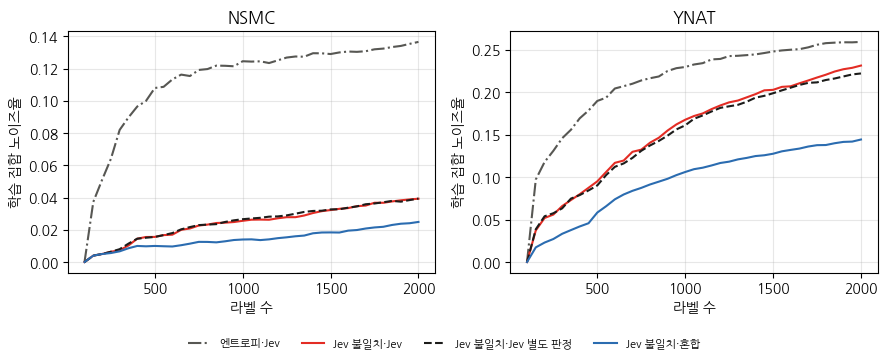

In [17]:
# ── 확증 편향과 노이즈 곡선 ────
BIAS_ARMS = ["엔트로피·Jev", "Jev 불일치·Jev", "Jev 불일치·Jev 별도 판정", "Jev 불일치·혼합", "Jev 불일치·사람"]
b = res[res.n_labeled < BUDGET].groupby(["data", "arm"], sort=False)[["batch_jev_wrong", "batch_bias", "batch_student_wrong"]].mean()
for name in DATA:
    print(f"\n{name} 질의 배치의 비율 (Jev 불일치·사람은 질의 판정의 Jev 라벨 기준, 시드·라운드 평균)")
    print(b.loc[name].loc[BIAS_ARMS].round(4).to_string())

STY17 = dict(zip(BIAS_ARMS, [(GRAY, "-."), (ACCENT, "-"), (INK, "--"), ("#2B6CB0", "-"), (GRAY2, ":")]))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, name in zip(axes, DATA):
    for arm in BIAS_ARMS[:4]:
        g = res[(res.data == name) & (res.arm == arm)].groupby("n_labeled").noise.mean()
        c, ls = STY17[arm]
        ax.plot(g.index, g.values, color=c, ls=ls, lw=1.5, label=arm)
    ax.set(title=name.upper(), xlabel="라벨 수", ylabel="학습 집합 노이즈율")
    ax.grid(alpha=0.3)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig("out/ch17_noise.png", dpi=200)

## 17.5 네 가지 조합의 전체 루프 실험

질의 2개(엔트로피, Jev 불일치)와 오라클 3개(사람, Jev, 혼합)의 조합을 학습 곡선과 비용으로 비교한다. 별도 판정 칸도 함께 싣는다. 사람 비용은 16장처럼 사람이 붙인 라벨 × 단가 + 검수 × 단가의 60%다. 토큰은 칸이 쓴 판정의 몫(질의 + 오라클)이다.


nsmc (label_acc = 질의 라벨 1,900개 정확도, cost_h = 사람 비용(원), tok = 칸이 쓴 Jev 입력 토큰 몫)
                   label_acc     ALC  ALC_std   final    cost_h          tok
arm                                                                         
엔트로피·사람               1.0000  0.7479   0.0061  0.7860  100000.0       0.0000
엔트로피·Jev              0.8562  0.7450   0.0047  0.7825    5000.0  155163.2000
엔트로피·혼합               0.9381  0.7528   0.0021  0.7902   16400.0  176475.8647
Jev 불일치·사람            1.0000  0.7711   0.0024  0.8063  100000.0  595828.2783
Jev 불일치·Jev           0.9586  0.7716   0.0029  0.8069    5000.0  600728.2462
Jev 불일치·Jev 별도 판정     0.9585  0.7715   0.0041  0.8084    5000.0  759661.8195
Jev 불일치·혼합            0.9738  0.7710   0.0026  0.8062   16400.0  606283.2904

ynat (label_acc = 질의 라벨 1,900개 정확도, cost_h = 사람 비용(원), tok = 칸이 쓴 Jev 입력 토큰 몫)
                   label_acc     ALC  ALC_std   final    cost_h           tok
arm                                                                  

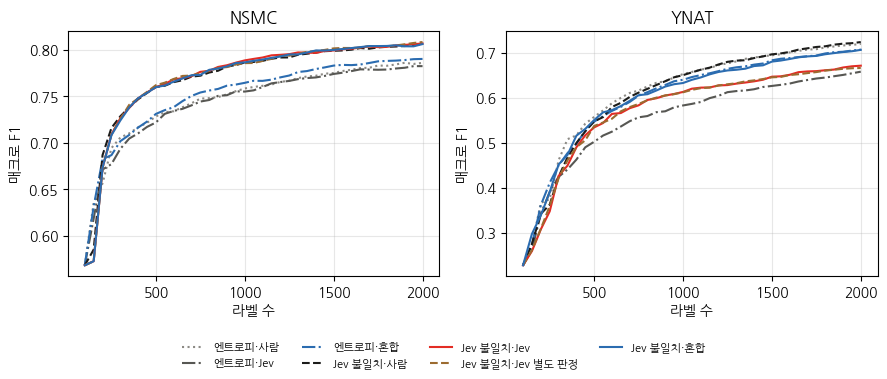

In [18]:
# ── 학습 곡선과 비교표 (표 17.1) ────
u = res.data.map(UNIT)
res["cost_h"] = np.where(res.arm.str.endswith("사람"), res.n_labeled, N_INIT) * u + REVIEW * res.reviews * u
res["tok"] = res.tok_q + res.tok_o

KEYS = list(ARMS)
STY = dict(zip(KEYS, [(GRAY2, ":"), (GRAY, "-."), ("#2B6CB0", "-."), (INK, "--"), (ACCENT, "-"), ("#9C6B30", "--"), ("#2B6CB0", "-")]))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, DATA):
    for arm in KEYS:
        g = res[(res.data == name) & (res.arm == arm)].groupby("n_labeled").f1.mean()
        c, ls = STY[arm]
        ax.plot(g.index, g.values, color=c, ls=ls, lw=1.5, label=arm)
    ax.set(title=name.upper(), xlabel="라벨 수", ylabel="매크로 F1")
    ax.grid(alpha=0.3)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.11, 1, 1))
fig.savefig("out/ch17_curves.png", dpi=200)

last = res[res.n_labeled == BUDGET].groupby(["data", "arm"], sort=False).agg(
    noise=("noise", "mean"), final=("f1", "mean"), cost_h=("cost_h", "mean"), tok=("tok", "mean"), tok_new=("tok_new", "mean"))
alcs = res.groupby(["data", "arm", "seed"], sort=False).apply(lambda x: alc(x.n_labeled.values, x.f1.values), include_groups=False)
tab1 = last.join(alcs.groupby(["data", "arm"], sort=False).agg(["mean", "std"]).rename(columns={"mean": "ALC", "std": "ALC_std"}))
tab1["label_acc"] = 1 - tab1.noise * BUDGET / (BUDGET - N_INIT)
for name in DATA:
    print(f"\n{name} (label_acc = 질의 라벨 1,900개 정확도, cost_h = 사람 비용(원), tok = 칸이 쓴 Jev 입력 토큰 몫)")
    print(tab1.loc[name][["label_acc", "ALC", "ALC_std", "final", "cost_h", "tok"]].round(4).to_string())

## 17.6 사람 개입 지점

에이전틱 루프에서도 사람이 맡는 자리가 남는다. 이 장과 4부의 결과로 자리마다 드는 사람 비용을 정리한다. 초기 라벨과 퓨샷 예시, 신뢰도 하위 라벨 검수, 종료 판단의 확인이다.

In [19]:
# ── 개입 지점별 사람 비용 ────
for name in DATA:
    x = tab1.loc[name]
    print(f"\n{name}: 초기 라벨 100개 {N_INIT * UNIT[name]:,}원 | 검수(혼합 칸, 라벨 2,000까지) "
          f"엔트로피 {x.loc['엔트로피·혼합', 'cost_h'] - N_INIT * UNIT[name]:,.0f}원, "
          f"Jev 불일치 {x.loc['Jev 불일치·혼합', 'cost_h'] - N_INIT * UNIT[name]:,.0f}원 | 사람 오라클 {x.loc['엔트로피·사람', 'cost_h']:,.0f}원")


nsmc: 초기 라벨 100개 5,000원 | 검수(혼합 칸, 라벨 2,000까지) 엔트로피 11,400원, Jev 불일치 11,400원 | 사람 오라클 100,000원

ynat: 초기 라벨 100개 8,000원 | 검수(혼합 칸, 라벨 2,000까지) 엔트로피 18,240원, Jev 불일치 18,240원 | 사람 오라클 160,000원


In [20]:
# ── 이 장이 쓴 Jev 입력 토큰 ────
print(f"이번에 새로 쓴 입력 토큰: {res[res.n_labeled == BUDGET].tok_new.sum():,.0f}")
print(res[res.n_labeled == BUDGET].groupby(["data", "arm"], sort=False).tok_new.sum().round(0).to_string())

이번에 새로 쓴 입력 토큰: 3,396,787
data  arm              
nsmc  엔트로피·사람                    0.0
      엔트로피·Jev                   0.0
      엔트로피·혼합                    0.0
      Jev 불일치·사람            209481.0
      Jev 불일치·Jev           167360.0
      Jev 불일치·Jev 별도 판정     903387.0
      Jev 불일치·혼합            105485.0
ynat  엔트로피·사람                    0.0
      엔트로피·Jev                   0.0
      엔트로피·혼합                    0.0
      Jev 불일치·사람            339470.0
      Jev 불일치·Jev           255793.0
      Jev 불일치·Jev 별도 판정    1238449.0
      Jev 불일치·혼합            177362.0
